# Week 5: Statistical and Time-Series Analysis of Electricity Consumption in Morocco
**Track 2: Data Science | AnalystLab Africa Experience Lab Internship**

This notebook walks through data inspection, descriptive statistics, time-series patterns and decomposition, environmental correlations, zone comparisons, and key findings using simple, readable Python code.


## Important Notes from the Data Dictionary
- **Sampling & Period:** 52,416 rows recorded every **10 minutes** from **2017-01-01 00:00:00** to **2017-12-30 23:50:00**.
- **Power Units:** `PowerConsumption_Zone1`, `PowerConsumption_Zone2`, and `PowerConsumption_Zone3` are given in **Kilowatt-Hours (kWh)**. We use **averages (means)** when summarizing typical hourly, daily, or monthly consumption rather than blindly summing every 10-minute reading.
- **Diffuse Flow Fields:** In `powerconsumption_datadictionary.csv`, `GeneralDiffuseFlows` and `DiffuseFlows` describe emission gases diffusing into the broader and local atmosphere.


## Task 1: Data Import and Exploration


In [1]:
import pandas as pd
import numpy as np
from scipy import stats
from statsmodels.tsa.seasonal import seasonal_decompose
import matplotlib.pyplot as plt

# Load the data dictionary and dataset
dictionary = pd.read_csv('powerconsumption_datadictionary.csv')
df = pd.read_csv('powerconsumption.csv')

print('Dataset shape (rows, columns):', df.shape)
print('Columns:', list(df.columns))
print('\nMissing values per column:\n', df.isnull().sum())
print('Duplicate rows:', df.duplicated().sum())

# Convert Datetime to datetime format and sort chronologically
df['Datetime'] = pd.to_datetime(df['Datetime'])
df = df.sort_values('Datetime').reset_index(drop=True)

# Check 10-minute interval consistency
intervals = df['Datetime'].diff().dropna()
print('\nInterval frequencies:\n', intervals.value_counts())
print('Date range:', df['Datetime'].min(), 'to', df['Datetime'].max())


Dataset shape (rows, columns): (52416, 9)
Columns: ['Datetime', 'Temperature', 'Humidity', 'WindSpeed', 'GeneralDiffuseFlows', 'DiffuseFlows', 'PowerConsumption_Zone1', 'PowerConsumption_Zone2', 'PowerConsumption_Zone3']

Missing values per column:
 Datetime                  0
Temperature               0
Humidity                  0
WindSpeed                 0
GeneralDiffuseFlows       0
DiffuseFlows              0
PowerConsumption_Zone1    0
PowerConsumption_Zone2    0
PowerConsumption_Zone3    0
dtype: int64
Duplicate rows: 0

Interval frequencies:
 Datetime
0 days 00:10:00    52415
Name: count, dtype: int64
Date range: 2017-01-01 00:00:00 to 2017-12-30 23:50:00


## Task 2: Statistical Summary Across Zones


In [2]:
zones = ['PowerConsumption_Zone1', 'PowerConsumption_Zone2', 'PowerConsumption_Zone3']

summary_list = []
for col in zones:
    s = df[col]
    q25, median, q75 = np.percentile(s, [25, 50, 75])
    summary_list.append({
        'Zone': col,
        'Mean': round(s.mean(), 2),
        'Median': round(median, 2),
        'Min': round(s.min(), 2),
        'Max': round(s.max(), 2),
        'Std_Dev': round(s.std(), 2),
        'Variance': round(s.var(), 2),
        'Q25': round(q25, 2),
        'Q75': round(q75, 2),
        'IQR': round(q75 - q25, 2),
        'Skewness': round(stats.skew(s), 2)
    })

stats_summary = pd.DataFrame(summary_list)
print(stats_summary.to_string(index=False))


                  Zone     Mean   Median      Min      Max  Std_Dev    Variance      Q25      Q75      IQR  Skewness
PowerConsumption_Zone1 32344.97 32265.92 13895.70 52204.40  7130.56 50844922.48 26310.67 37309.02 10998.35      0.23
PowerConsumption_Zone2 21042.51 20823.17  8560.08 37408.86  5201.47 27055247.43 16980.77 24713.72  7732.95      0.33
PowerConsumption_Zone3 17835.41 16415.12  5935.17 47598.33  6622.17 43853070.60 13129.33 21624.10  8494.77      1.02


## Task 3: Time-Series Analysis
We resample 10-minute readings into **hourly** and **daily** averages so daily routines, weekly/monthly cycles, and seasonal components are clear and easy to interpret.


Zone 1 average consumption by hour (Top 3 peak hours):
Hour
20    43822.6
19    42795.9
21    42216.5
Name: PowerConsumption_Zone1, dtype: float64

Zone 1 average consumption by hour (Lowest 3 hours):
Hour
6    23203.6
5    23437.6
7    24038.4
Name: PowerConsumption_Zone1, dtype: float64

Average consumption by day of week:
            PowerConsumption_Zone1  PowerConsumption_Zone2  \
DayOfWeek                                                   
Monday                    32615.4                 21280.1   
Tuesday                   32713.0                 21518.6   
Wednesday                 32871.8                 21627.4   
Thursday                  32842.5                 21845.2   
Friday                    32339.0                 21461.0   
Saturday                  32253.0                 20586.0   
Sunday                    30780.1                 18979.4   

           PowerConsumption_Zone3  
DayOfWeek                          
Monday                    17809.1  
Tuesday       

C:\Users\HomePC\AppData\Local\Temp\ipykernel_16852\171233092.py:27: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


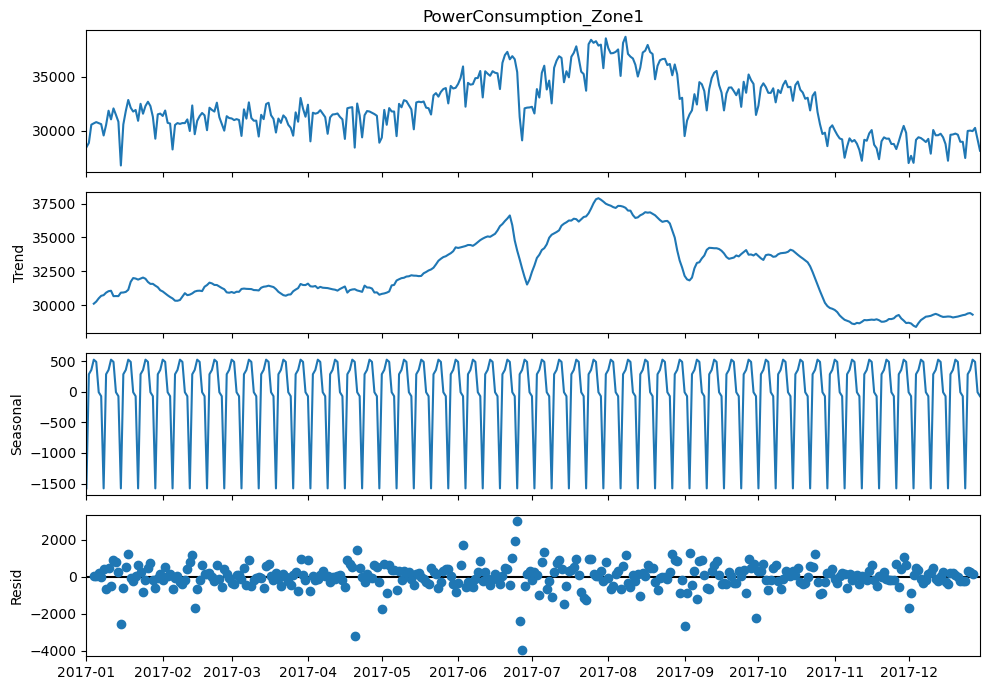

In [3]:
df_ts = df.set_index('Datetime')

# Aggregate to hourly and daily averages
hourly = df_ts[zones + ['Temperature', 'Humidity', 'WindSpeed']].resample('h').mean()
daily = df_ts[zones + ['Temperature', 'Humidity', 'WindSpeed']].resample('D').mean().dropna()

# Add calendar features for easy grouping
df['Hour'] = df['Datetime'].dt.hour
df['DayOfWeek'] = df['Datetime'].dt.day_name()
df['Month'] = df['Datetime'].dt.month

print('Zone 1 average consumption by hour (Top 3 peak hours):')
print(df.groupby('Hour')['PowerConsumption_Zone1'].mean().nlargest(3).round(1))

print('\nZone 1 average consumption by hour (Lowest 3 hours):')
print(df.groupby('Hour')['PowerConsumption_Zone1'].mean().nsmallest(3).round(1))

dow_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
print('\nAverage consumption by day of week:\n', df.groupby('DayOfWeek')[zones].mean().reindex(dow_order).round(1))

print('\nAverage consumption by month:\n', df.groupby('Month')[zones].mean().round(1))

# Additive seasonal decomposition on daily Zone 1 consumption (weekly 7-day cycle)
decomp = seasonal_decompose(daily['PowerConsumption_Zone1'], model='additive', period=7)
fig = decomp.plot()
fig.set_size_inches(10, 7)
plt.tight_layout()
plt.show()


## Task 4: Environmental Statistical Analysis
We calculate both **Pearson** and **Spearman** correlations on hourly data to measure linear and rank-based associations with `Temperature`, `Humidity`, and `WindSpeed`. Remember that correlation does **not** prove causation.


In [4]:
env_cols = ['Temperature', 'Humidity', 'WindSpeed']

for z in zones:
    for e in env_cols:
        r_p, p_p = stats.pearsonr(hourly[z], hourly[e])
        r_s, p_s = stats.spearmanr(hourly[z], hourly[e])
        print(f'{z} vs {e:11s} -> Pearson r={r_p:+.3f} (p={p_p:.2e}), Spearman rho={r_s:+.3f} (p={p_s:.2e})')


PowerConsumption_Zone1 vs Temperature -> Pearson r=+0.444 (p=0.00e+00), Spearman rho=+0.435 (p=0.00e+00)
PowerConsumption_Zone1 vs Humidity    -> Pearson r=-0.291 (p=8.69e-170), Spearman rho=-0.302 (p=3.60e-183)
PowerConsumption_Zone1 vs WindSpeed   -> Pearson r=+0.170 (p=2.32e-57), Spearman rho=+0.115 (p=5.35e-27)
PowerConsumption_Zone2 vs Temperature -> Pearson r=+0.385 (p=2.30e-306), Spearman rho=+0.380 (p=1.34e-298)
PowerConsumption_Zone2 vs Humidity    -> Pearson r=-0.298 (p=1.68e-178), Spearman rho=-0.311 (p=1.73e-195)
PowerConsumption_Zone2 vs WindSpeed   -> Pearson r=+0.148 (p=5.69e-44), Spearman rho=+0.094 (p=1.67e-18)
PowerConsumption_Zone3 vs Temperature -> Pearson r=+0.492 (p=0.00e+00), Spearman rho=+0.438 (p=0.00e+00)
PowerConsumption_Zone3 vs Humidity    -> Pearson r=-0.235 (p=5.30e-110), Spearman rho=-0.213 (p=2.17e-90)
PowerConsumption_Zone3 vs WindSpeed   -> Pearson r=+0.281 (p=3.09e-158), Spearman rho=+0.084 (p=4.83e-15)


## Task 5: Comparative Zone Analysis & Visuals
We use one-way **ANOVA** and the non-parametric **Kruskal-Wallis** test to check whether the three zones differ significantly, then plot monthly, hourly, day-of-week, and temperature patterns.


ANOVA: F = 75029.00, p = 0.00e+00
Kruskal-Wallis: H = 76069.59, p = 0.00e+00


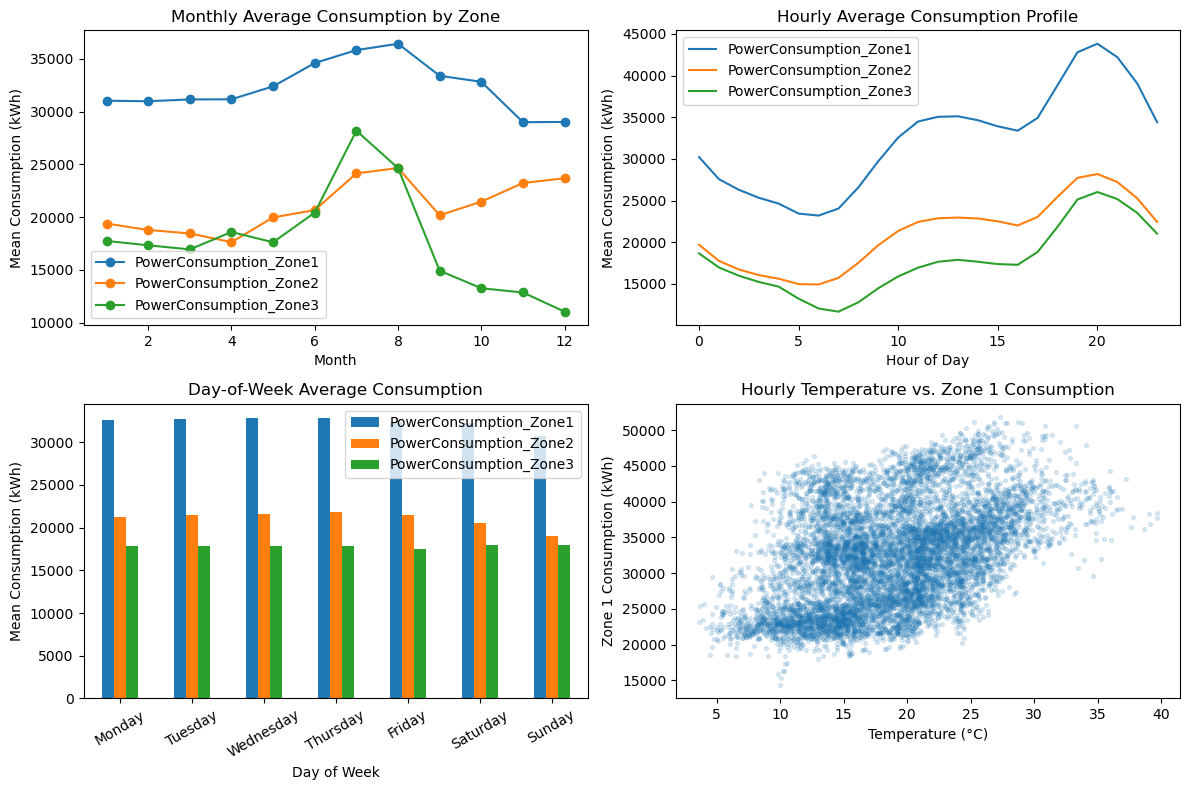

In [5]:
f_stat, p_anova = stats.f_oneway(df[zones[0]], df[zones[1]], df[zones[2]])
kw_stat, p_kw = stats.kruskal(df[zones[0]], df[zones[1]], df[zones[2]])
print(f'ANOVA: F = {f_stat:.2f}, p = {p_anova:.2e}')
print(f'Kruskal-Wallis: H = {kw_stat:.2f}, p = {p_kw:.2e}')

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

df.groupby('Month')[zones].mean().plot(ax=axes[0, 0], marker='o')
axes[0, 0].set_title('Monthly Average Consumption by Zone')
axes[0, 0].set_xlabel('Month')
axes[0, 0].set_ylabel('Mean Consumption (kWh)')

df.groupby('Hour')[zones].mean().plot(ax=axes[0, 1])
axes[0, 1].set_title('Hourly Average Consumption Profile')
axes[0, 1].set_xlabel('Hour of Day')
axes[0, 1].set_ylabel('Mean Consumption (kWh)')

df.groupby('DayOfWeek')[zones].mean().reindex(dow_order).plot(kind='bar', ax=axes[1, 0])
axes[1, 0].set_title('Day-of-Week Average Consumption')
axes[1, 0].set_xlabel('Day of Week')
axes[1, 0].set_ylabel('Mean Consumption (kWh)')
axes[1, 0].tick_params(axis='x', rotation=30)

axes[1, 1].scatter(hourly['Temperature'], hourly['PowerConsumption_Zone1'], alpha=0.15, s=8)
axes[1, 1].set_title('Hourly Temperature vs. Zone 1 Consumption')
axes[1, 1].set_xlabel('Temperature (°C)')
axes[1, 1].set_ylabel('Zone 1 Consumption (kWh)')

plt.tight_layout()
plt.show()


## Task 6: Key Findings, Limitations & Recommendations
- **Highest & Most Variable Zone:** Zone 1 has the highest average demand (**32,344.97 kWh**) and widest spread (**Std = 7,130.56 kWh**), while Zone 3 is right-skewed (**1.02**) with a sharp summer jump in July (**28,194.1 kWh**).
- **Daily & Seasonal Cycles:** Demand is lowest in early morning hours (**5:00–7:00**), peaks in the evening (**19:00–21:00**), dips slightly on Sundays, and rises during **July–August**.
- **Environmental Links:** Temperature shows a moderate positive correlation with consumption (e.g., Zone 1 Pearson $r = 0.444$), humidity shows a mild negative correlation, and wind speed shows a weak positive correlation.
- **Limitations:** Only one year (**2017**) is included, exact zone names or holiday/tariff data are not provided, and hourly readings have autocorrelation.
- **Recommendations:** Plan extra evening reserve capacity (**19:00–21:00**), prepare cooling/grid capacity ahead of summer peaks (**July–August**), and tailor load management to each zone's profile.
